# Fake News Detection using a Bidirectional LSTM (TensorFlow / Keras)
Dataset: Kaggle *Fake News Detection* (`fake.csv` + `true.csv`, columns: `title, text, subject, date`)

**How to run in Colab:** Runtime → Run all. When the upload cell appears, select **fake.csv** and **true.csv**.

**Pipeline:** load → clean → balanced ~2000 subset → split → tokenize + pad → BiLSTM → train → metrics → confusion matrix → unseen predictions

## 0. Environment setup

In [3]:
import os, re, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)

SAMPLE_SIZE = 2000   # ~2,000 labelled articles (1000 fake + 1000 real)
MAX_WORDS   = 10000  # vocabulary size
MAX_LEN     = 300    # padded sequence length
EMBED_DIM   = 64

TensorFlow: 2.21.0
GPU available: False


## 1. Upload and load the dataset

In [4]:
# Upload fake.csv and true.csv (skip the upload if the files are already in the Colab folder)
try:
    from google.colab import files
    if not (os.path.exists("fake.csv") and os.path.exists("true.csv")):
        files.upload()
except ImportError:
    print("Not running in Colab - expecting fake.csv and true.csv in the current folder.")

def find_file(name):
    for f in os.listdir("."):
        if f.lower() == name:
            return f
    raise FileNotFoundError(f"{name} not found. Upload it first.")

fake = pd.read_csv(find_file("fake.csv")); fake["label"] = 1   # 1 = FAKE
real = pd.read_csv(find_file("true.csv")); real["label"] = 0   # 0 = REAL

print("fake:", fake.shape, "| true:", real.shape)
print("\nMissing values (fake):\n", fake.isnull().sum())
print("\nMissing values (true):\n", real.isnull().sum())
fake.head(3)

fake: (23481, 5) | true: (21417, 5)

Missing values (fake):
 title      0
text       0
subject    0
date       0
label      0
dtype: int64

Missing values (true):
 title      0
text       0
subject    0
date       0
label      0
dtype: int64


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",1
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",1
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",1


## 2. Handle missing values and preprocess text

In [5]:
df = pd.concat([fake, real], ignore_index=True)

# Missing values: fill empty fields, then drop rows that still have no usable text
df["title"] = df["title"].fillna("")
df["text"]  = df["text"].fillna("")
df["content"] = (df["title"] + " " + df["text"]).str.strip()
df = df[df["content"].str.len() > 20]
df = df.drop_duplicates(subset="content")

def clean_text(t):
    t = str(t).lower()
    t = re.sub(r"^.{0,80}?\(reuters\)\s*-?\s*", " ", t)   # remove "CITY (Reuters) -" dateline
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)           # URLs
    t = re.sub(r"<.*?>", " ", t)                             # HTML tags
    t = re.sub(r"\breuters\b", " ", t)                      # leftover source name
    t = re.sub(r"[^a-z\s]", " ", t)                         # punctuation / digits
    t = re.sub(r"\s+", " ", t).strip()                      # extra whitespace
    return t

# Balanced subset of ~2000 articles
per_class = SAMPLE_SIZE // 2
df = (df.groupby("label", group_keys=False)
        .apply(lambda g: g.sample(min(len(g), per_class), random_state=SEED))
        .sample(frac=1, random_state=SEED)
        .reset_index(drop=True))

df["clean"] = df["content"].apply(clean_text)
df = df[df["clean"].str.len() > 0].reset_index(drop=True)

print("Subset size:", len(df))
print(df["label"].value_counts().rename({0: "REAL", 1: "FAKE"}))
print("\nExample cleaned article:\n", df["clean"].iloc[0][:300], "...")

/tmp/ipykernel_853/1602337971.py:23: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), per_class), random_state=SEED))


Subset size: 2000
label
FAKE    1000
REAL    1000
Name: count, dtype: int64

Example cleaned article:
 costco raises minimum wage for workers as republicans continue to do nothing costco cares more about the american workforce than republicans do a few years ago costco answered the call to help struggling workers by raising the wages of their own employees to an hour nearly a full increase above the  ...


## 3. Train/test split, tokenization and padding

In [6]:
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df["clean"].values, df["label"].values.astype("float32"),
    test_size=0.2, random_state=SEED, stratify=df["label"])

# --- Tokenizer: built from TRAIN data only (prevents data leakage) ---
counter = collections.Counter(w for t in X_train_txt for w in t.split())
vocab = ["<PAD>", "<OOV>"] + [w for w, _ in counter.most_common(MAX_WORDS - 2)]
word_index = {w: i for i, w in enumerate(vocab)}      # 0 = padding, 1 = unknown

def texts_to_padded(texts, maxlen=MAX_LEN):
    """Words -> integer ids -> padded/truncated to a fixed length."""
    out = np.zeros((len(texts), maxlen), dtype="int32")
    for i, t in enumerate(texts):
        ids = [word_index.get(w, 1) for w in t.split()][:maxlen]
        out[i, :len(ids)] = ids                          # post-padding with zeros
    return out

X_train = texts_to_padded(X_train_txt)
X_test  = texts_to_padded(X_test_txt)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("First sequence (first 20 ids):", X_train[0][:20])

X_train: (1600, 300) | X_test: (400, 300)
First sequence (first 20 ids): [4023  231 3837  804    1  156   17  170   10  135   95   11  290 1823
  782  744   26   46  322   56]


## 4. Model: Bidirectional LSTM

In [7]:
model = models.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(input_dim=MAX_WORDS, output_dim=EMBED_DIM, mask_zero=True),
    layers.Bidirectional(layers.LSTM(64)),
    layers.Dropout(0.5),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),      # probability that the article is FAKE
])

model.compile(loss="binary_crossentropy",
              optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
              metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 300, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 710,209 (2.71 MB)

 Trainable params: 710,209 (2.71 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Train

In [8]:
early_stop = callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history = model.fit(X_train, y_train,
                    validation_split=0.1,
                    epochs=15, batch_size=32,
                    callbacks=[early_stop], verbose=1)

Epoch 1/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 17s 304ms/step - accuracy: 0.6861 - loss: 0.6543 - val_accuracy: 0.7937 - val_loss: 0.5344
Epoch 2/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 20s 298ms/step - accuracy: 0.9403 - loss: 0.2236 - val_accuracy: 0.9688 - val_loss: 0.0671
Epoch 3/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 13s 296ms/step - accuracy: 0.9903 - loss: 0.0391 - val_accuracy: 0.9812 - val_loss: 0.0408
Epoch 4/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 21s 296ms/step - accuracy: 0.9937 - loss: 0.0261 - val_accuracy: 0.9937 - val_loss: 0.0130
Epoch 5/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 20s 298ms/step - accuracy: 0.9986 - loss: 0.0050 - val_accuracy: 1.0000 - val_loss: 0.0085
Epoch 6/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 21s 304ms/step - accuracy: 1.0000 - loss: 0.0014 - val_accuracy: 0.9875 - val_loss: 0.0204
Epoch 7/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 13s 298ms/step - accuracy: 1.0000 - loss: 6.8053e-04 - val_accuracy: 0.9812 - val_loss: 0.0339
Epoch 8/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 14s 303ms/step - accuracy: 1.0000 - loss: 4.9813e-04 - 

## 6. Evaluate (accuracy, precision, recall, F1)

Accuracy : 0.9750
Precision: 0.9750
Recall   : 0.9750
F1-score : 0.9750

              precision    recall  f1-score   support

        REAL       0.97      0.97      0.97       200
        FAKE       0.97      0.97      0.97       200

    accuracy                           0.97       400
   macro avg       0.97      0.97      0.97       400
weighted avg       0.97      0.97      0.97       400



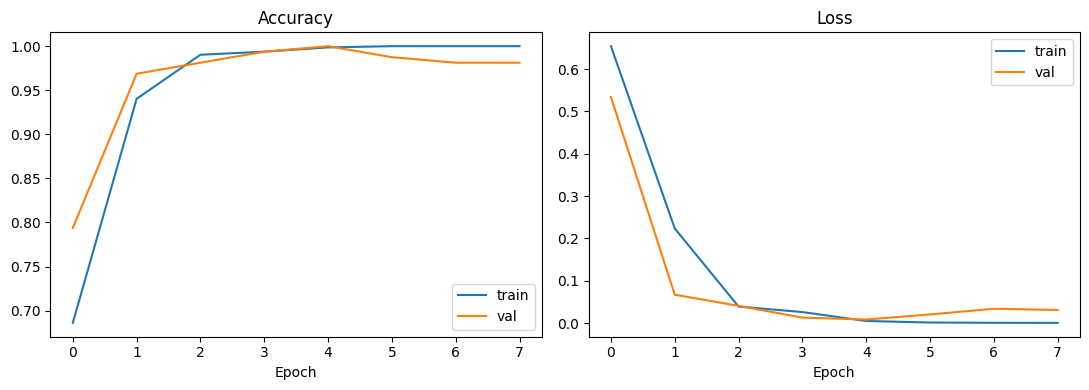

In [9]:
y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=["REAL", "FAKE"]))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="val")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig("training_curves.png", dpi=150); plt.show()

## 7. Confusion matrix

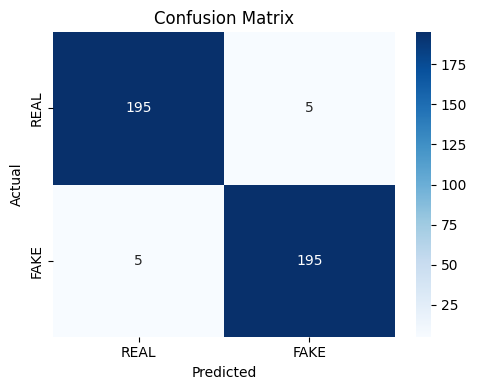

Real classified correctly: 195 | Real wrongly flagged as fake: 5
Fake missed (called real): 5 | Fake caught correctly: 195


In [10]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["REAL", "FAKE"], yticklabels=["REAL", "FAKE"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=150); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Real classified correctly: {tn} | Real wrongly flagged as fake: {fp}")
print(f"Fake missed (called real): {fn} | Fake caught correctly: {tp}")

## 8. Predictions on unseen articles

In [11]:
def predict_news(article):
    seq = texts_to_padded([clean_text(article)])
    p = float(model.predict(seq, verbose=0)[0][0])
    return ("FAKE" if p >= 0.5 else "REAL"), (p if p >= 0.5 else 1 - p)

unseen_articles = [
    "BREAKING: Scientists confirm that drinking hot water with lemon cures all types of cancer, "
    "but doctors and big pharma are hiding the truth from you. Share before it gets deleted!",
    "WASHINGTON - The Federal Reserve left interest rates unchanged on Wednesday, saying inflation "
    "had eased and the labor market remained solid, according to a statement after its policy meeting.",
    "Shocking leaked memo proves the moon landing was staged in a studio and officials have "
    "finally admitted it to anonymous insiders. Wake up people!",
]

print("=== Unseen (hand-written) articles ===")
for art in unseen_articles:
    label, conf = predict_news(art)
    print(f"[{label} | {conf*100:.1f}%] {art[:90]}...")

print("\n=== Held-out test articles ===")
for i in range(5):
    actual = "FAKE" if y_test[i] == 1 else "REAL"
    label, conf = predict_news(X_test_txt[i])
    print(f"Actual: {actual} | Predicted: {label} ({conf*100:.1f}%) | {X_test_txt[i][:80]}...")

=== Unseen (hand-written) articles ===
[FAKE | 99.9%] BREAKING: Scientists confirm that drinking hot water with lemon cures all types of cancer,...
[REAL | 100.0%] WASHINGTON - The Federal Reserve left interest rates unchanged on Wednesday, saying inflat...
[FAKE | 98.7%] Shocking leaked memo proves the moon landing was staged in a studio and officials have fin...

=== Held-out test articles ===
Actual: REAL | Predicted: REAL (99.8%) | china and india are development opportunities for each other not threats xi tell...
Actual: REAL | Predicted: REAL (100.0%) | president donald trump s tax reform plans won partial support on friday when rep...
Actual: FAKE | Predicted: FAKE (100.0%) | hillary clinton and bill blasio s racist joke may have just lost her the black v...
Actual: REAL | Predicted: REAL (100.0%) | aftershocks likely from september test detected from north korea nuclear site us...
Actual: REAL | Predicted: REAL (100.0%) | u s president donald trump said on wednesday he was not 

## 9. Save the model and outputs (optional download)

In [12]:
model.save("fake_news_lstm.keras")
try:
    from google.colab import files
    for f in ["fake_news_lstm.keras", "confusion_matrix.png", "training_curves.png"]:
        files.download(f)
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>